# Module 1 · Notebook 3: The experiment

**Question: how small should $\varepsilon$ be in a gradient check, and does the precision (float64 vs float32) matter?**

Notebooks 1 and 2 used $\varepsilon = 10^{-6}$ in float64 without justifying it. Intuition says "smaller is always more accurate". It is not: past a point, a smaller $\varepsilon$ makes the check **worse**.

| Step | What we do |
|---|---|
| 1 | Theory: two errors that pull in opposite directions |
| 2 | Experiment on a 1-D function: sweep $\varepsilon$ from $10^{-12}$ to $10^{-1}$ |
| 3 | The same on a real network (tiny MLP + cross-entropy) |
| 4 | Why it matters: which bugs can each precision actually catch? |

In [1]:
import sys
import numpy as np
import matplotlib.pyplot as plt

print("python", sys.version.split()[0], "| numpy", np.__version__)

# chart style: recessive grid and axes, ink for text, one color per precision
SURFACE, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
COLOR = {"float64": "#2a78d6", "float32": "#eb6834"}
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "text.color": INK, "axes.titlecolor": INK,
    "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
    "lines.linewidth": 2, "font.size": 10, "legend.frameon": False,
})

python 3.12.15 | numpy 2.5.3


## Step 1: Theory, two errors pulling in opposite directions

**Truncation error (the math).** Taylor expansion shows how wrong each formula is even with perfect arithmetic:

$$\text{forward: } \frac{f(x+\varepsilon) - f(x)}{\varepsilon} = f'(x) + \underbrace{\tfrac{\varepsilon}{2} f''(x)}_{\propto\, \varepsilon} + \dots \qquad \text{central: } \frac{f(x+\varepsilon) - f(x-\varepsilon)}{2\varepsilon} = f'(x) + \underbrace{\tfrac{\varepsilon^2}{6} f'''(x)}_{\propto\, \varepsilon^2} + \dots$$

In the central formula the $f''$ terms cancel, which is why it is far more accurate for the same $\varepsilon$. This error **shrinks** as $\varepsilon$ shrinks.

**Rounding error (the computer).** Every $f(\cdot)$ is computed with a relative error of about $u$, the *machine epsilon* ($u \approx 2.2 \times 10^{-16}$ in float64, $1.2 \times 10^{-7}$ in float32). Subtracting two nearly equal numbers keeps that absolute error while the true difference gets tiny, and dividing by $\varepsilon$ magnifies it: about $u / \varepsilon$. This error **grows** as $\varepsilon$ shrinks.

**Total error and the sweet spot** (treating $f$ and its derivatives as order 1):

| Formula | Total error | Best $\varepsilon$ | Best achievable error |
|---|---|---|---|
| forward | $\varepsilon + u/\varepsilon$ | $\sqrt{u}$ | $\sim\sqrt{u}$ |
| central | $\varepsilon^2 + u/\varepsilon$ | $u^{1/3}$ | $\sim u^{2/3}$ |

In [2]:
print(f"{'precision':10s} {'u (machine eps)':>16s} | {'forward: best eps':>18s} {'best err':>9s} | {'central: best eps':>18s} {'best err':>9s}")
for name, dtype in [("float64", np.float64), ("float32", np.float32)]:
    u = np.finfo(dtype).eps
    print(f"{name:10s} {u:16.1e} | {np.sqrt(u):18.1e} {np.sqrt(u):9.1e} | {u ** (1/3):18.1e} {u ** (2/3):9.1e}")

precision   u (machine eps) |  forward: best eps  best err |  central: best eps  best err
float64             2.2e-16 |            1.5e-08   1.5e-08 |            6.1e-06   3.7e-11
float32             1.2e-07 |            3.5e-04   3.5e-04 |            4.9e-03   2.4e-05


These are the **predictions**. Now we measure.

## Step 2: Experiment on a 1-D function

$f(x) = \sin(x)\, e^x$ at $x = 1.3$. We know its exact derivative, $f'(x) = e^x(\sin x + \cos x)$, so we can measure the true error of each finite-difference estimate for 67 values of $\varepsilon$, in both precisions.

Every operation in the finite difference (the shift $x \pm \varepsilon$, the function evaluations, the subtraction) runs in the chosen precision. The exact derivative is always computed in float64.

In [3]:
def f(x):
    return np.sin(x) * np.exp(x)

def df_exact(x):
    return np.exp(x) * (np.sin(x) + np.cos(x))

x0 = 1.3
exact = df_exact(x0)
eps_grid = np.logspace(-12, -1, 67)

def fd_error(dtype, kind):
    x = dtype(x0)
    errs = []
    for e in eps_grid:
        e = dtype(e)
        if kind == "central":
            g = (f(x + e) - f(x - e)) / (dtype(2) * e)
        else:
            g = (f(x + e) - f(x)) / e
        errs.append(abs(float(g) - exact) / abs(exact))
    return np.maximum(np.array(errs), 1e-17)    # floor only so log-scale plots never see an exact 0

errs_1d = {(p, k): fd_error(dt, k)
           for p, dt in [("float64", np.float64), ("float32", np.float32)]
           for k in ["forward", "central"]}

print(f"{'precision':10s} {'formula':8s} | {'measured best eps':>18s} {'error there':>12s} | {'predicted best eps':>19s}")
for (p, k), errs in errs_1d.items():
    u = np.finfo(np.float64 if p == "float64" else np.float32).eps
    pred = np.sqrt(u) if k == "forward" else u ** (1 / 3)
    i = errs.argmin()
    print(f"{p:10s} {k:8s} | {eps_grid[i]:18.1e} {errs[i]:12.1e} | {pred:19.1e}")

precision  formula  |  measured best eps  error there |  predicted best eps
float64    forward  |            4.6e-09      1.1e-09 |             1.5e-08
float64    central  |            1.0e-05      1.3e-11 |             6.1e-06
float32    forward  |            2.2e-04      4.3e-05 |             3.5e-04
float32    central  |            2.2e-03      6.4e-06 |             4.9e-03


## Step 3: The same on a real network

A 1-D function is clean. Does the same picture hold for a real gradient check, i.e. a tiny MLP (4 → 8 → 3, tanh, cross-entropy, **67 parameters**) checked against all parameters at once?

For the "exact" gradient we need a reference that does not depend on finite differences. Here it is the **backward pass written by hand** in float64: exactly the chain rule that our autograd engine performed for us in notebook 2. (We confirm it agrees with a float64 check below.)

The relative error is the norm-based one from notebook 2: $\lVert g_{\text{ref}} - g_{\text{num}} \rVert \,/\, (\lVert g_{\text{ref}} \rVert + \lVert g_{\text{num}} \rVert)$.

In [4]:
rng = np.random.default_rng(0)
N, D, H, C = 16, 4, 8, 3
X = rng.standard_normal((N, D))
y = rng.integers(0, C, N)
P = {"W1": rng.standard_normal((D, H)) * 0.5, "b1": rng.standard_normal(H) * 0.1,
     "W2": rng.standard_normal((H, C)) * 0.5, "b2": rng.standard_normal(C) * 0.1}
print("parameters:", sum(v.size for v in P.values()))

def loss_fn(P, X, y):
    # Runs entirely in whatever dtype P and X are in.
    h = np.tanh(X @ P["W1"] + P["b1"])
    z = h @ P["W2"] + P["b2"]
    z = z - z.max(axis=1, keepdims=True)
    log_probs = z - np.log(np.exp(z).sum(axis=1, keepdims=True))
    return -log_probs[np.arange(len(y)), y].mean()

def hand_backward(P, X, y, bug=0.0):
    # The chain rule written out by hand (float64). `bug` lets Step 4 inject a small error.
    h = np.tanh(X @ P["W1"] + P["b1"])
    z = h @ P["W2"] + P["b2"]
    p = np.exp(z - z.max(axis=1, keepdims=True))
    p /= p.sum(axis=1, keepdims=True)
    dz = (p - np.eye(C)[y]) / len(y)              # softmax + cross-entropy, combined
    dh = dz @ P["W2"].T
    da = dh * (1 - h**2) * (1 + bug)              # tanh'(a) = 1 - tanh(a)^2
    return {"W1": X.T @ da, "b1": da.sum(0), "W2": h.T @ dz, "b2": dz.sum(0)}

def numerical_grad(P, X, y, dtype, eps):
    Pd = {k: v.astype(dtype) for k, v in P.items()}
    Xd = X.astype(dtype)
    e = dtype(eps)
    G = {}
    for k, v in Pd.items():
        g = np.zeros(v.shape)
        for idx in np.ndindex(v.shape):
            old = v[idx]
            v[idx] = old + e; lp = loss_fn(Pd, Xd, y)
            v[idx] = old - e; lm = loss_fn(Pd, Xd, y)
            v[idx] = old
            g[idx] = float(lp - lm) / (2 * float(e))   # the subtraction happens in `dtype`
        G[k] = g
    return G

def rel_err(A, B):
    a = np.concatenate([A[k].ravel() for k in P])
    b = np.concatenate([B[k].ravel() for k in P])
    return np.linalg.norm(a - b) / max(np.linalg.norm(a) + np.linalg.norm(b), 1e-300)

g_ref = hand_backward(P, X, y)
print(f"hand backward vs float64 check at eps=1e-6: rel_err = {rel_err(g_ref, numerical_grad(P, X, y, np.float64, 1e-6)):.1e}")

parameters: 67
hand backward vs float64 check at eps=1e-6: rel_err = 4.6e-10


In [5]:
eps_mlp = np.logspace(-10, -1, 28)
errs_mlp = {p: np.array([rel_err(g_ref, numerical_grad(P, X, y, dt, e)) for e in eps_mlp])
            for p, dt in [("float64", np.float64), ("float32", np.float32)]}

best = {}
for p, errs in errs_mlp.items():
    i = errs.argmin()
    best[p] = (eps_mlp[i], errs[i])
    print(f"{p}: best eps = {eps_mlp[i]:.1e}, rel_err there = {errs[i]:.1e}   | at eps=1e-6: {np.interp(-6, np.log10(eps_mlp), errs):.1e}")

float64: best eps = 1.0e-05, rel_err there = 5.3e-11   | at eps=1e-6: 4.6e-10
float32: best eps = 1.0e-02, rel_err there = 3.0e-05   | at eps=1e-6: 2.5e-01


### The chart

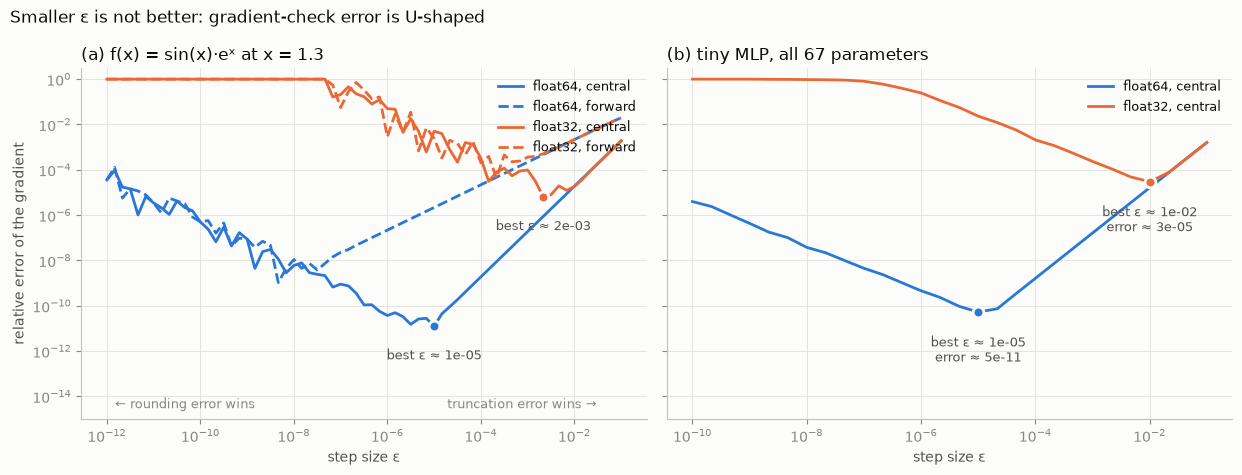

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.8), sharey=True)

# (a) 1-D function: both formulas, both precisions
ax = axes[0]
for p in ["float64", "float32"]:
    ax.loglog(eps_grid, errs_1d[(p, "central")], color=COLOR[p], label=f"{p}, central")
    ax.loglog(eps_grid, errs_1d[(p, "forward")], color=COLOR[p], ls="--", label=f"{p}, forward")
    i = errs_1d[(p, "central")].argmin()
    ax.scatter(eps_grid[i], errs_1d[(p, "central")][i], s=60, color=COLOR[p],
               edgecolor=SURFACE, linewidth=2, zorder=3)
    ax.annotate(f"best ε ≈ {eps_grid[i]:.0e}", (eps_grid[i], errs_1d[(p, "central")][i]),
                xytext=(0, -16), textcoords="offset points", ha="center", va="top", color=INK2, fontsize=9)
ax.text(1.5e-12, 3e-15, "← rounding error wins", color=MUTED, fontsize=9)
ax.text(3e-2, 3e-15, "truncation error wins →", color=MUTED, fontsize=9, ha="right")
ax.set_title("(a) f(x) = sin(x)·eˣ at x = 1.3", loc="left")
ax.set_xlabel("step size ε")
ax.set_ylabel("relative error of the gradient")
ax.set_ylim(1e-15, 3)
ax.legend(loc="upper right", fontsize=9)

# (b) tiny MLP: central difference, both precisions
ax = axes[1]
for p in ["float64", "float32"]:
    ax.loglog(eps_mlp, errs_mlp[p], color=COLOR[p], label=f"{p}, central")
    e_best, r_best = best[p]
    ax.scatter(e_best, r_best, s=60, color=COLOR[p], edgecolor=SURFACE, linewidth=2, zorder=3)
    ax.annotate(f"best ε ≈ {e_best:.0e}\nerror ≈ {r_best:.0e}", (e_best, r_best),
                xytext=(0, -16), textcoords="offset points", ha="center", va="top", color=INK2, fontsize=9)
ax.set_title("(b) tiny MLP, all 67 parameters", loc="left")
ax.set_xlabel("step size ε")
ax.legend(loc="upper right", fontsize=9)

fig.suptitle("Smaller ε is not better: gradient-check error is U-shaped", x=0.01, ha="left", fontsize=12)
plt.tight_layout()
plt.show()

## Step 4: Why it matters, which bugs can each check catch?

A gradient check is a bug detector. Its **noise floor** (the best error from Step 3) decides the smallest bug it can see: a bug that changes the gradient by less than the floor is invisible.

We inject a bug of relative size $\delta$ into the hand-written backward (the tanh derivative becomes $(1 - t^2)(1 + \delta)$), then run each precision's check at its own best $\varepsilon$.

In [7]:
G_num = {p: numerical_grad(P, X, y, dt, best[p][0]) for p, dt in [("float64", np.float64), ("float32", np.float32)]}

print(f"{'bug size δ':>11s} | {'float64 rel_err':>16s} {'':8s} | {'float32 rel_err':>16s}")
print(f"{'none':>11s} | {rel_err(g_ref, G_num['float64']):16.1e} {'(floor)':8s} | {rel_err(g_ref, G_num['float32']):16.1e} (floor)")
for delta in [1e-1, 1e-2, 1e-3, 1e-4, 1e-5, 1e-6]:
    g_bug = hand_backward(P, X, y, bug=delta)
    e64, e32 = rel_err(g_bug, G_num["float64"]), rel_err(g_bug, G_num["float32"])
    see64 = "caught" if e64 > 10 * best["float64"][1] else "missed"
    see32 = "caught" if e32 > 10 * best["float32"][1] else "missed"
    print(f"{delta:11.0e} | {e64:16.1e} {see64:8s} | {e32:16.1e} {see32}")

 bug size δ |  float64 rel_err          |  float32 rel_err
       none |          5.3e-11 (floor)  |          3.0e-05 (floor)
      1e-01 |          3.2e-02 caught   |          3.2e-02 caught
      1e-02 |          3.2e-03 caught   |          3.2e-03 caught
      1e-03 |          3.2e-04 caught   |          3.3e-04 caught
      1e-04 |          3.2e-05 caught   |          4.9e-05 missed
      1e-05 |          3.2e-06 caught   |          3.1e-05 missed
      1e-06 |          3.2e-07 caught   |          3.0e-05 missed


"Caught" here means the error is at least **10× above that precision's floor**, so it clearly stands out from noise.

## Findings

**1. The error is U-shaped, and the theory predicts where the bottom is.** Every measured best $\varepsilon$ landed within about 2–3× of the prediction from Step 1 ($\sqrt{u}$ for forward, $u^{1/3}$ for central). Left of the bottom, rounding error dominates; right of it, truncation error does.

**2. Central differences are ~100× more accurate than forward** in float64 (best error ~1e-11 vs ~1e-9), for the same cost per parameter (2 evaluations vs 1 + a shared baseline).

**3. Float32 is a trap.** Its best possible error is ~3e-5 on the MLP, at a large $\varepsilon \approx 10^{-2}$. With the "usual" $\varepsilon = 10^{-6}$, the float32 check reports **25% error on a correct gradient**: it would make correct code look broken. Below $\varepsilon \approx 10^{-8}$, $x \pm \varepsilon$ rounds back to $x$ in float32, the estimate is exactly 0, and the error is 100% (the flat line at the top of the chart).

**4. Precision decides which bugs you can see.** The float64 check caught a bug as small as $\delta = 10^{-6}$ (error 3.2e-7, ~6,000× above its floor). The float32 check missed every bug of size $10^{-4}$ or smaller, because they are buried in its own noise floor of ~3e-5.

**The rule this module uses from here on:**
- run gradient checks in **float64**, with **central** differences;
- $\varepsilon$ between $10^{-6}$ and $10^{-5}$;
- a correct gradient gives a relative error around $10^{-9}$ to $10^{-11}$; anything above ~$10^{-6}$ is a bug until proven otherwise.

(Training itself can run in lower precision; that is the mixed-precision module later in the lab. The *check* needs float64.)